# Workload analysis

A thin viewing layer. Every number and figure here is produced by the project's
own modules — this notebook imports them rather than re-deriving anything, so it
cannot drift from `reports/`.

- Analysis prose and tables: [`reports/`](../reports/)
- Decisions, with alternatives and outcomes: [`DECISIONS.md`](../DECISIONS.md)
- Final report: [`reports/final_report.md`](../reports/final_report.md)

Run from the repository root, with `challenge_data/` extracted.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, "../analysis")

import figures

ctx = figures.load_context("../challenge_data")
print(f"training steps : {len(ctx.y_train)}")
print(f"detected period: {ctx.period} steps = {ctx.period * 5} minutes")
increments = {k: round(v, 4) for k, v in ctx.band_increments.items()}
print(f"band quantile  : {ctx.nominal_q:.3f}")
print(f"band increments: {increments}")

training steps : 110
detected period: 12 steps = 60 minutes
band quantile  : 0.875
band increments: {'1-6': 0.3639, '7-12': 0.3685, '13-24': 0.3685}


## 1. The training series

The whole fleet moves inside a 0.8-point band. The shaded window is the bump
(steps 53–72); the hollow marks are the recurring hourly dip.

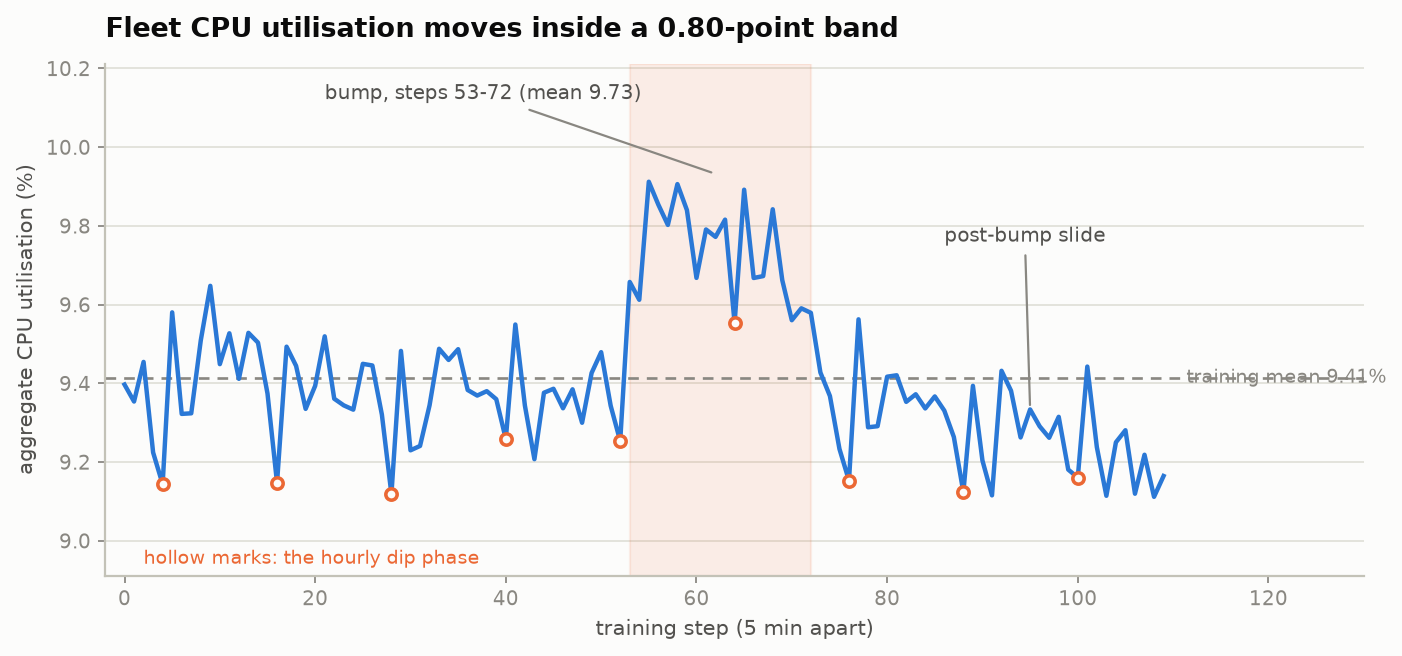

In [2]:
figures.fig_training_series(ctx);

## 2. The hourly cycle

A one-step dip and rebound, 0.34 points peak-to-trough — about 2.8× a typical
step change. Subtracting this profile halves step-to-step volatility and lifts
lag-1 autocorrelation from 0.662 to 0.879.

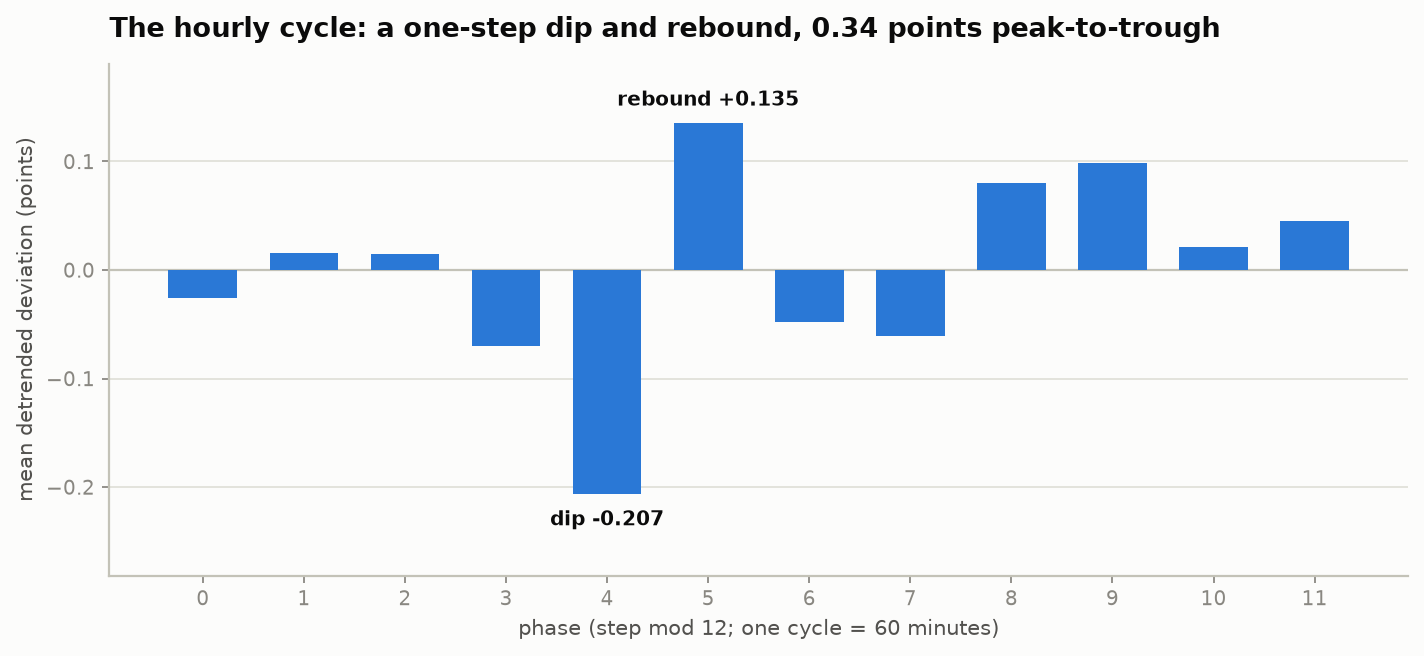

In [3]:
figures.fig_phase_profile(ctx);

## 3. How far ahead is this workload predictable?

Skill against the long-run training mean, by horizon step, across the 13
expanding-window folds. Persistence loses its edge at step 9.

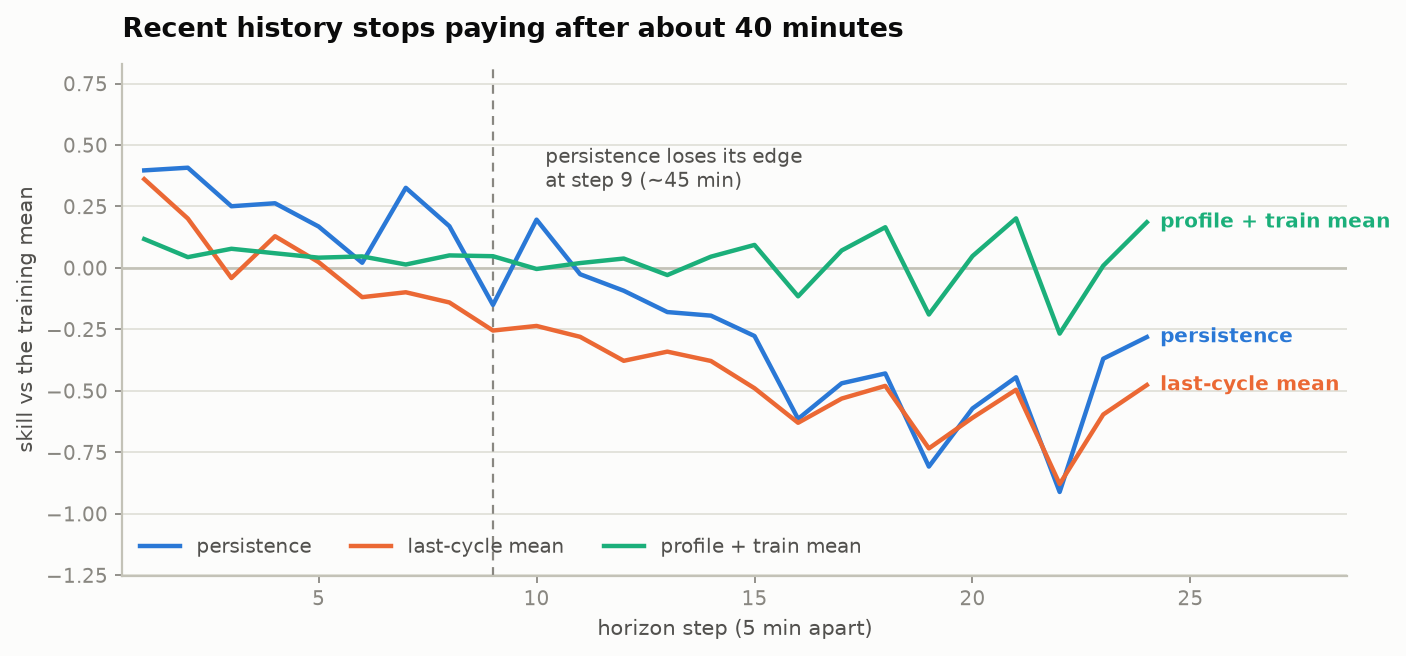

In [4]:
figures.fig_skill_by_horizon(ctx);

## 4. The holdout

The frozen model over-forecast a continuing decline and placed fourth of five.
`DECISIONS.md` entry 22, written before the holdout was scored, predicted this
failure. The band never breached — because the point forecast was biased high,
which makes 0/24 uninformative about the band's calibration.

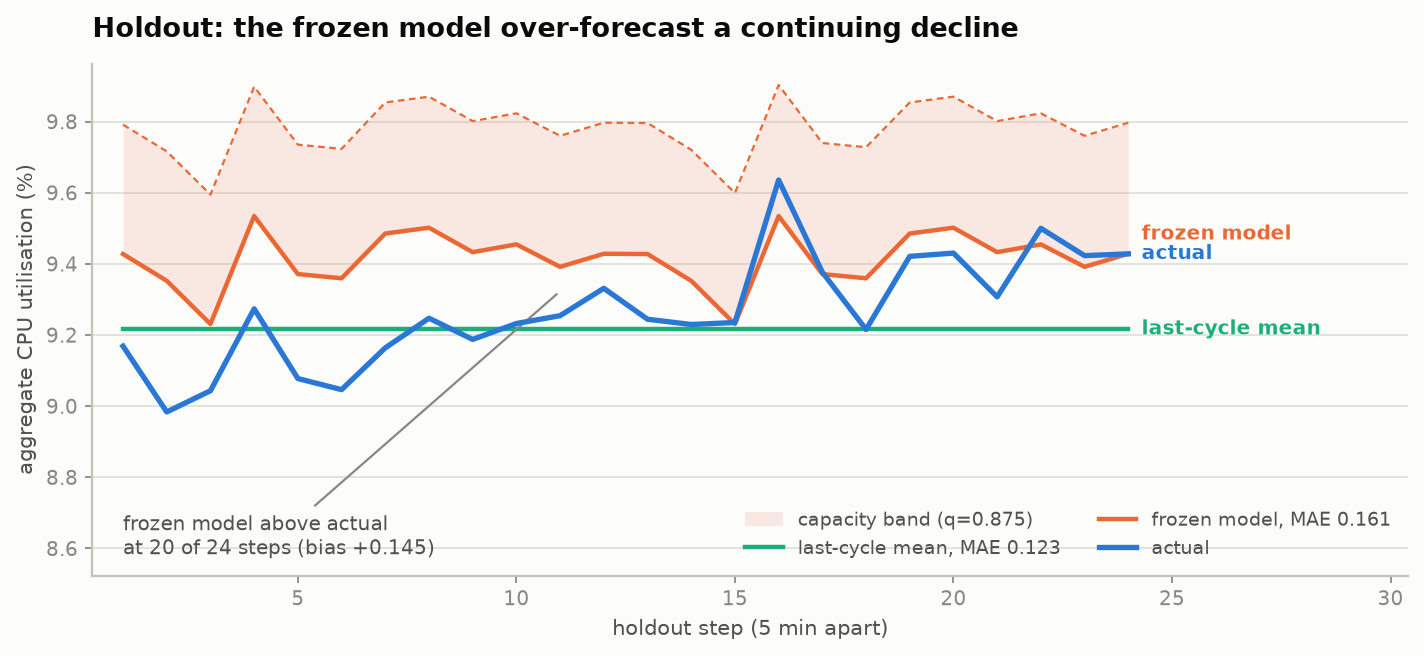

In [5]:
figures.fig_holdout(ctx);

## 5. Demand concentration

Capacity risk lives in the hot tail, not the fleet mean: ~2% of VMs run above
50% utilisation while the fleet sits at 9.4%.

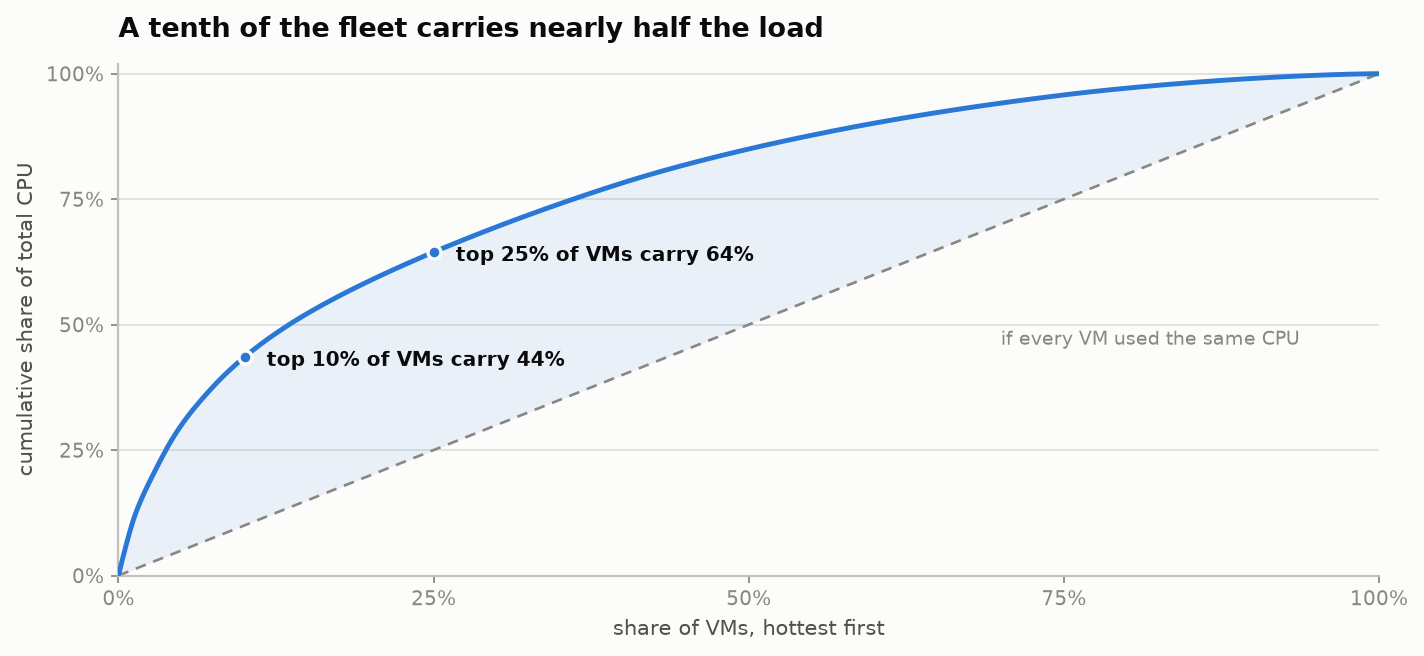

In [6]:
figures.fig_concentration(ctx);

## 6. Net versus gross movement

Each aggregate move is a small residual of movement about four times larger
underneath it, and roughly half the fleet moves *against* the aggregate each
time. Measuring concentration on the net move alone overstates it three- to
fourfold.

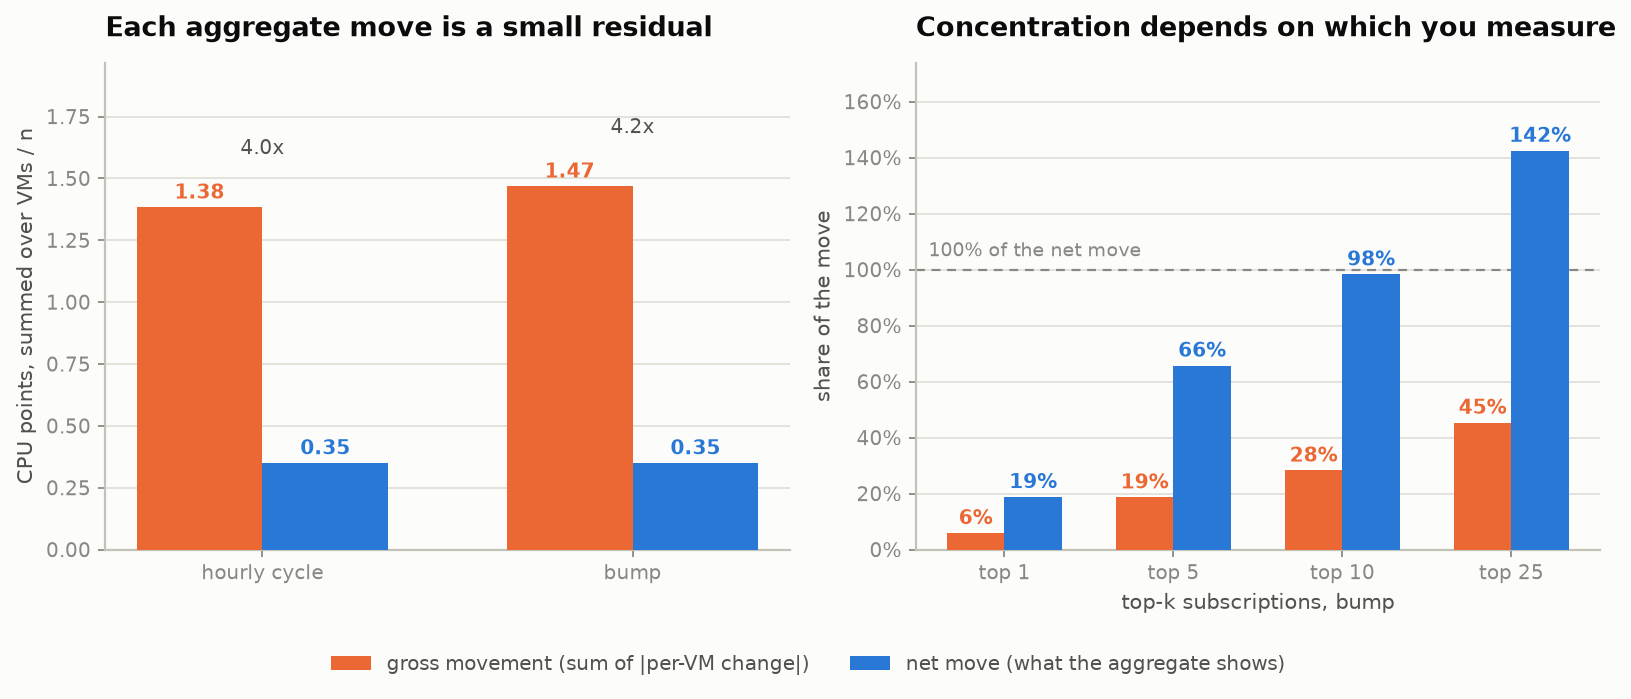

In [7]:
figures.fig_net_vs_gross(ctx);

---

### Reproducing everything

```bash
python -m pytest -q
python -m cwfc.predict --data challenge_data --output predictions.csv
python -m cwfc.score_holdout --data challenge_data --predictions predictions.csv
python analysis/01_data_and_workload.py
python analysis/02_cycle_attribution.py
python analysis/03_validation_and_policy.py
python analysis/04_core_weighted.py
python analysis/figures.py
```